# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [4]:

# TODO 1: voxel count and storage
nx, ny, nz = 512, 512, 300
n_voxels = nx * ny * nz
scan_mb = n_voxels * 2 / 1e6  # 16 bits = 2 bytes per voxel

# TODO 2: physical extent and voxel volume
extent_mm = (nx * 0.5, ny * 0.5, nz * 1.0)
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3: rendering sample counts
samples_per_frame = nx * nz * ny
samples_video = samples_per_frame * 120

# TODO 4: early ray termination
samples_video_ert = samples_video * 0.65

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")


78,643,200 voxels = 157.3 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 6,134,169,600


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_

Ignoring anisotropic voxel spacing would distort the anatomy in coronal and sagittal views because the voxel dimensions differ along the three axes. Structures could appear stretched or compressed, and their apparent shapes and physical measurements would be inaccurate. Correct aspect-ratio handling is therefore necessary for undistorted multiplanar reconstruction.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z, y, x): (28, 40, 41)
Detected lesion voxels: 431


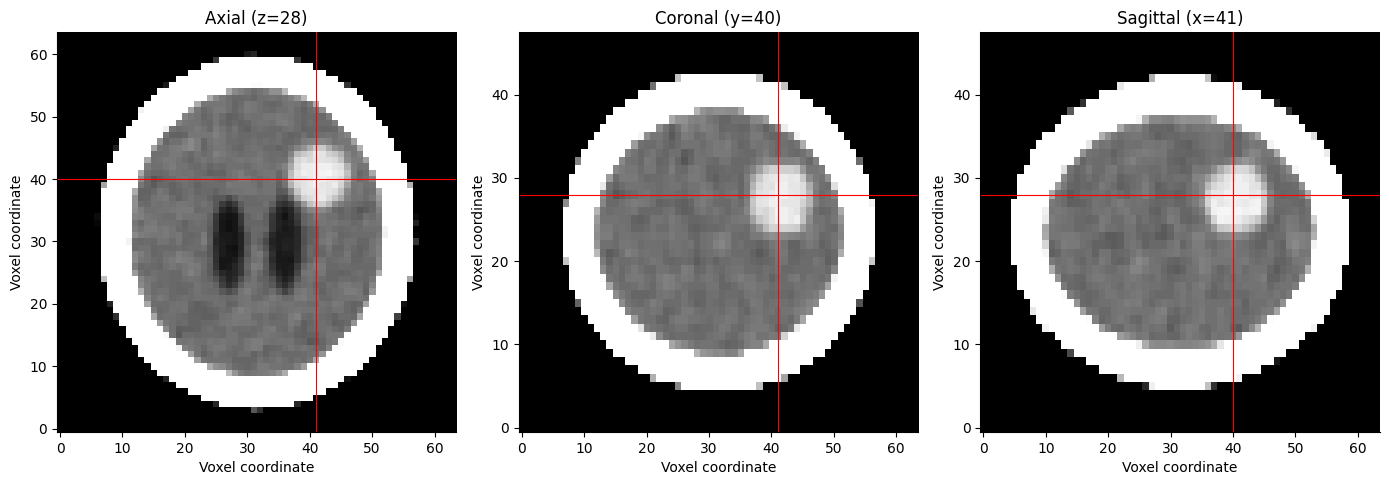

Centroid error: 2.92 mm


In [5]:

def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1: identify candidate lesion voxels without using labels
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside

# TODO 2: keep the largest connected component
components, n_components = ndimage.label(candidates)
sizes = np.bincount(components.ravel())
sizes[0] = 0
largest_component = np.argmax(sizes)
lesion = components == largest_component

cz, cy, cx = np.round(
    ndimage.center_of_mass(lesion)
).astype(int)

print(f"Lesion centroid (z, y, x): ({cz}, {cy}, {cx})")
print(f"Detected lesion voxels: {lesion.sum()}")

# TODO 3: plot axial, coronal and sagittal slices
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

# Axial: fixed z
axes[0].imshow(window(vol[cz, :, :], 80, 40),
               cmap="gray", origin="lower", aspect="equal")
axes[0].axhline(cy, color="red", linewidth=0.8)
axes[0].axvline(cx, color="red", linewidth=0.8)
axes[0].set_title(f"Axial (z={cz})")

# Coronal: fixed y
axes[1].imshow(window(vol[:, cy, :], 80, 40),
               cmap="gray", origin="lower", aspect=ASPECT)
axes[1].axhline(cz, color="red", linewidth=0.8)
axes[1].axvline(cx, color="red", linewidth=0.8)
axes[1].set_title(f"Coronal (y={cy})")

# Sagittal: fixed x
axes[2].imshow(window(vol[:, :, cx], 80, 40),
               cmap="gray", origin="lower", aspect=ASPECT)
axes[2].axhline(cz, color="red", linewidth=0.8)
axes[2].axvline(cy, color="red", linewidth=0.8)
axes[2].set_title(f"Sagittal (x={cx})")

for ax in axes:
    ax.set_xlabel("Voxel coordinate")
    ax.set_ylabel("Voxel coordinate")

plt.tight_layout()
plt.show()

# TODO 4: evaluation only
truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
detected_centroid = np.array([cz, cy, cx])
centroid_error_mm = np.linalg.norm(
    (detected_centroid - truth_centroid) * np.array(SPACING)
)
print(f"Centroid error: {centroid_error_mm:.2f} mm")


**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

The erosion step removes voxels near the inner skull boundary, where partial-volume effects can mix intensities from adjacent tissues. A voxel containing both bone and brain may have an intensity that falls within the candidate tumour range. Since different tissues can have overlapping CT intensity ranges, intensity thresholding alone can incorrectly include boundary voxels. Erosion reduces these false positives by restricting detection to the interior of the brain.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,Threshold_HU,Voxel_Count,Volume_mL,Dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


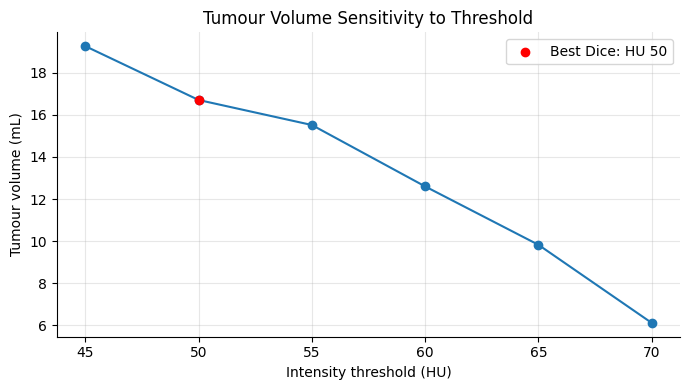

Volume range across thresholds: 6.12–19.26 mL
Best Dice threshold: 50 HU


In [6]:

truth = labels == 5
rows = []
thresholds = [45, 50, 55, 60, 65, 70]

# TODO 1 & 2
for c in thresholds:
    threshold_mask = vol > c
    components, _ = ndimage.label(threshold_mask)

    component_id = components[cz, cy, cx]
    region = components == component_id if component_id else np.zeros_like(
        threshold_mask
    )

    voxel_count = int(region.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000

    intersection = np.logical_and(region, truth).sum()
    denominator = voxel_count + truth.sum()
    dice = 2 * intersection / denominator if denominator else 0

    rows.append({
        "Threshold_HU": c,
        "Voxel_Count": voxel_count,
        "Volume_mL": volume_ml,
        "Dice": dice
    })

table = pd.DataFrame(rows)
display(table)

# TODO 3: plot volume versus threshold and mark best Dice
best_index = table["Dice"].idxmax()
best_threshold = table.loc[best_index, "Threshold_HU"]
best_volume = table.loc[best_index, "Volume_mL"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["Threshold_HU"], table["Volume_mL"], marker="o")
ax.scatter([best_threshold], [best_volume],
           color="red", zorder=3, label=f"Best Dice: HU {best_threshold}")
ax.set_xlabel("Intensity threshold (HU)")
ax.set_ylabel("Tumour volume (mL)")
ax.set_title("Tumour Volume Sensitivity to Threshold")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# TODO 4
min_volume = table["Volume_mL"].min()
max_volume = table["Volume_mL"].max()
print(f"Volume range across thresholds: {min_volume:.2f}–{max_volume:.2f} mL")
print(f"Best Dice threshold: {best_threshold} HU")


**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

In a real clinical setting, I would select the threshold using radiologist-reviewed CT images, the tumour's visible boundaries and consistency with other imaging evidence. I would compare the segmentations at several reasonable thresholds rather than assuming one threshold is exact. The volume plot and a segmentation overlay could show how the estimated volume changes with the threshold. I would report the selected estimate alongside the observed range and explain that segmentation uncertainty can affect treatment planning.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

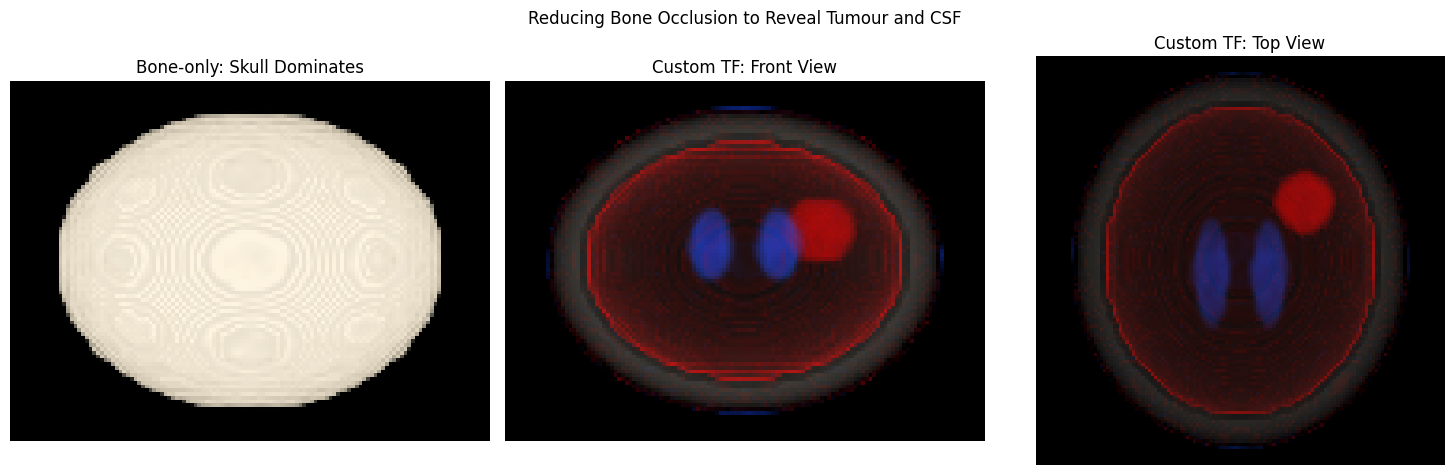

In [7]:

bone_tf = make_tf([
    (-1000, (0, 0, 0), 0),
    (200, (0, 0, 0), 0),
    (400, (1, 0.95, 0.85), 0.3),
    (1500, (1, 1, 1), 0.6)
])

# TODO 2: custom transfer function
tumour_tf = make_tf([
    (-1100, (0, 0, 0), 0.0),
    (0, (0, 0, 0), 0.0),
    (4, (0.1, 0.2, 1.0), 0.01),
    (12, (0.1, 0.3, 1.0), 0.04),
    (20, (0.1, 0.3, 1.0), 0.01),
    (30, (0, 0, 0), 0.0),
    (45, (0, 0, 0), 0.0),
    (49, (1.0, 0.0, 0.0), 0.02),
    (65, (1.0, 0.0, 0.0), 0.06),
    (80, (1.0, 0.0, 0.0), 0.02),
    (100, (0, 0, 0), 0.0),
    (300, (0, 0, 0), 0.005),
    (400, (0.9, 0.85, 0.75), 0.005),
    (1500, (1, 1, 1), 0.005)
])

# TODO 1 & 3: render bone, tumour TF front and top views
bone_front, bone_alpha = render(vol, bone_tf, axis=1)
tumour_front, tumour_front_alpha = render(vol, tumour_tf, axis=1)
tumour_top, tumour_top_alpha = render(vol, tumour_tf, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

axes[0].imshow(np.clip(bone_front, 0, 1), origin="lower")
axes[0].set_title("Bone-only: Skull Dominates")

axes[1].imshow(np.clip(tumour_front, 0, 1), origin="lower")
axes[1].set_title("Custom TF: Front View")

axes[2].imshow(np.clip(tumour_top, 0, 1), origin="lower")
axes[2].set_title("Custom TF: Top View")

for ax in axes:
    ax.axis("off")

# TODO 4
fig.suptitle("Reducing Bone Occlusion to Reveal Tumour and CSF")
plt.tight_layout()
plt.show()


**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

The faint red rim is caused by the partial-volume effect and overlapping intensity ranges, which can make boundary voxels appear similar to tumour tissue. A threshold-based segmentation or isosurface extraction can help remove the unwanted rim by explicitly isolating the region of interest. A transfer function alone cannot reliably distinguish two different tissues when their CT intensities overlap, because it assigns colour and opacity based on intensity rather than anatomical identity.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The detected lesion is located in the upper portion of the volume, toward the back and positive-x side, with an approximate centroid of (28, 40, 41) in voxel coordinates. Across the six tested intensity thresholds, the estimated tumour volume ranges from 6.12 to 19.26 mL, demonstrating that the chosen threshold strongly affects the measurement. I recommend opening the meeting with the three-plane MPR, because axial, coronal and sagittal slices expose internal anatomy and show the lesion's position through linked cross-hairs. The segmentation and volume plot can then support measurement and discussion of threshold sensitivity, followed by the 3-D rendering to show surrounding structures. One limitation of the 3-D render is that overlapping CT intensity ranges can cause unwanted tissues to appear similar to the tumour, while opacity accumulation can obscure internal structures.